Install PLY and Graphviz

In [ ]:
!pip install ply graphviz

Import Libraries

In [ ]:
import sys
import ply.lex as lex
import ply.yacc as yacc
from graphviz import Digraph

# Fix for Google Colab
sys.modules['__main__'].__file__ = 'syntax_tree.py'

Define Lexer

In [ ]:
tokens = (
    'NUMBER',
    'ID',
    'PLUS',
    'MINUS',
    'TIMES',
    'DIVIDE',
    'LPAREN',
    'RPAREN'
)

t_PLUS = r'\+'
t_MINUS = r'-'
t_TIMES = r'\*'
t_DIVIDE = r'/'
t_LPAREN = r'\('
t_RPAREN = r'\)'

def t_NUMBER(t):
    r'\d+(\.\d+)?'

    if '.' in t.value:
        t.value = float(t.value)
    else:
        t.value = int(t.value)

    return t

def t_ID(t):
    r'[a-zA-Z_][a-zA-Z0-9_]*'
    return t

t_ignore = ' \t'

def t_newline(t):
    r'\n+'
    t.lexer.lineno += len(t.value)

def t_error(t):
    print(f"Illegal character '{t.value[0]}' at line {t.lineno}, position {t.lexpos}")
    t.lexer.skip(1)

lexer = lex.lex()

Define Syntax Tree Node

In [ ]:
class Node:
    def __init__(self, value, left=None, right=None):
        self.value = value
        self.left = left
        self.right = right

Define Parser

In [ ]:
precedence = (
    ('left', 'PLUS', 'MINUS'),
    ('left', 'TIMES', 'DIVIDE'),
)

def p_expression_number(p):
    'expression : NUMBER'
    p[0] = Node(str(p[1]))

def p_expression_id(p):
    'expression : ID'
    p[0] = Node(p[1])

def p_expression_paren(p):
    'expression : LPAREN expression RPAREN'
    p[0] = p[2]

def p_expression_binop(p):
    '''expression : expression PLUS expression
                  | expression MINUS expression
                  | expression TIMES expression
                  | expression DIVIDE expression'''

    p[0] = Node(p[2], p[1], p[3])

def p_error(p):
    if p is None:
        print("Syntax error at EOF")
    else:
        print(f"Syntax error at '{p.value}'")

parser = yacc.yacc(write_tables=False, debug=False)

Read Arithmetic Expression

In [ ]:
expression = input(
    "Enter an arithmetic expression (using +, -, *, / only): "
)

lexer.lineno = 1
tree = parser.parse(expression, lexer=lexer)

Enter an arithmetic expression (using +, -, *, / only): a+b*c/d-e*(2+x)


Generate Syntax Tree

In [ ]:
def draw_tree(node, graph=None, parent=None):
    if graph is None:
        graph = Digraph()

    if node is None:
        return graph

    node_id = str(id(node))

    graph.node(node_id, node.value)

    if parent is not None:
        graph.edge(parent, node_id)

    if node.left is not None:
        draw_tree(node.left, graph, node_id)

    if node.right is not None:
        draw_tree(node.right, graph, node_id)

    return graph

Display Syntax Tree

Valid expression.
Syntax Tree:


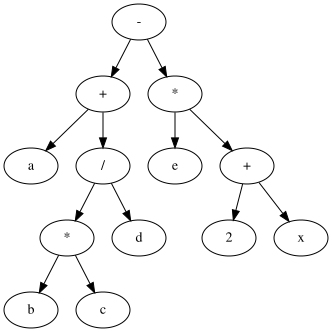

In [ ]:
if tree is not None:
    print("Valid expression.")
    print("Syntax Tree:")

    graph = draw_tree(tree)
    display(graph)

Test Valid Expression

Valid expression.


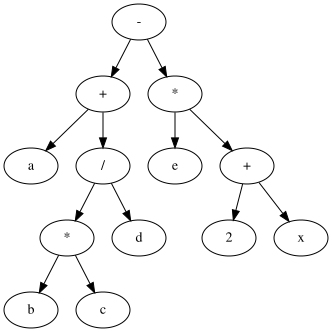

In [ ]:
expression = "a+b*c/d-e*(2+x)"

lexer.lineno = 1
tree = parser.parse(expression, lexer=lexer)

if tree is not None:
    print("Valid expression.")
    display(draw_tree(tree))

Test Another Valid Expression

Valid expression.


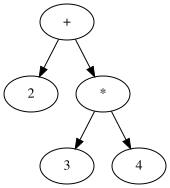

In [ ]:
expression = "2+3*4"

lexer.lineno = 1
tree = parser.parse(expression, lexer=lexer)

if tree is not None:
    print("Valid expression.")
    display(draw_tree(tree))

Test Invalid Expression

In [ ]:
expression = "a+b*"

lexer.lineno = 1
tree = parser.parse(expression, lexer=lexer)

Syntax error at EOF


Test Illegal Character

In [ ]:
expression = "a+b@c"

lexer.lineno = 1
tree = parser.parse(expression, lexer=lexer)

Illegal character '@' at line 1, position 3
Syntax error at 'c'


# Algorithm

1. Read an arithmetic expression from the user.
2. The lexical analyzer scans the expression and generates tokens.
3. Numbers, identifiers, operators and parentheses are recognized.
4. The parser checks the expression according to the grammar.
5. Operator precedence is applied so that * and / have higher precedence than + and -.
6. For every binary operator, create a tree node containing the operator.
7. The operands become the left and right child nodes.
8. If the expression is invalid, display an appropriate error message.
9. If the expression is valid, generate and display the syntax tree.

# Grammar

expression → expression + expression
           | expression - expression
           | expression * expression
           | expression / expression
           | ( expression )
           | ID
           | NUMBER

Precedence:

* and / have higher precedence than + and -.